# NB01 - Praproses Dataset

Notebook ini menyiapkan citra dari 12 kelas buah pada subset `train`. Tahapannya meliputi inventarisasi, deduplikasi intra-kelas menggunakan *perceptual hash*, *center crop*, *resize* 512 × 512 piksel, verifikasi hasil, dan ekspor laporan.

In [3]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [4]:
from __future__ import annotations

import json
import sys
import time
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv, write_json

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
SELECTED_CLASSES = (
    "001apple", "002orange", "003pear", "004tomato",
    "005strawberry", "006banana", "007watermelon", "009peach",
    "010pomegranate", "012starfruit", "014lemon", "015pomelo",
)
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
METHOD_VERSION = "dataset-preparation-3.0"


## Tahap 2 - Inventarisasi Dataset Raw

In [5]:
def list_images(directory: Path) -> list[Path]:
    return sorted(path for path in directory.rglob("*") if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS)

inventory_rows = []
for source_class in SELECTED_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    paths = list_images(class_dir) if class_dir.exists() else []
    inventory_rows.append({"source_class": source_class, "subset": SUBSET, "raw_image_count": len(paths), "source_directory": str(class_dir)})

inventory = pd.DataFrame(inventory_rows)
if (inventory["raw_image_count"] == 0).any():
    missing = inventory.loc[inventory["raw_image_count"] == 0, "source_class"].tolist()
    raise RuntimeError(f"Kelas tanpa citra pada subset train: {missing}")

print(inventory.to_string(index=False))
print(f"Total citra raw: {int(inventory['raw_image_count'].sum())}")

  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\Colorblind_correction\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\Colorblind_correction\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\Colorblind_correction\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\Colorblind_correction\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\Colorblind_correction\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\Colorblind_correction\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\Colorblind_correction\research\datasets\raw\fruits\007watermelon\train
      009peach  train              434       C:\Colorblind_correction\research\datasets\

## Tahap 3 - Deduplikasi pHash per Kelas

In [6]:
def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as image:
        return imagehash.phash(image.convert("RGB"))

def deduplicate_paths(paths: list[Path], threshold: int) -> tuple[list[Path], list[dict]]:
    retained: list[Path] = []
    retained_hashes: list[tuple[Path, imagehash.ImageHash]] = []
    duplicates: list[dict] = []
    for path in paths:
        current_hash = compute_phash(path)
        match = next(((kept_path, int(current_hash - kept_hash)) for kept_path, kept_hash in retained_hashes if int(current_hash - kept_hash) <= threshold), None)
        if match is None:
            retained.append(path)
            retained_hashes.append((path, current_hash))
        else:
            duplicates.append({"duplicate_file": path.name, "retained_file": match[0].name, "phash_distance": match[1]})
    return retained, duplicates

candidates: list[tuple[str, Path]] = []
deduplication_rows: list[dict] = []
for source_class in SELECTED_CLASSES:
    retained, duplicates = deduplicate_paths(list_images(RAW_DATASET_DIR / source_class / SUBSET), PHASH_THRESHOLD)
    candidates.extend((source_class, path) for path in retained)
    deduplication_rows.extend({"source_class": source_class, **item} for item in duplicates)

print(f"Citra setelah deduplikasi: {len(candidates)}")
print(f"Duplikasi yang dihapus: {len(deduplication_rows)}")

Citra setelah deduplikasi: 3604
Duplikasi yang dihapus: 136


## Tahap 4 - Center Crop, Resize, dan Pembuatan Manifest

In [7]:
def center_crop_resize(source_path: Path, destination_path: Path, size: int) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")

manifest_rows: list[dict] = []
error_rows: list[dict] = []
for source_class, source_path in candidates:
    output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
    try:
        started = time.perf_counter()
        center_crop_resize(source_path, output_path, OUTPUT_SIZE)
        manifest_rows.append({"subset": SUBSET, "source_class": source_class, "source_file_name": source_path.name, "source_path": str(source_path), "output_file_name": output_path.name, "output_path": str(output_path), "output_sha256": sha256_file(output_path), "processing_seconds": round(time.perf_counter() - started, 6), "method_version": METHOD_VERSION})
    except Exception as error:
        error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

manifest = pd.DataFrame(manifest_rows).sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
if manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil diproses.")
print(f"Citra berhasil diproses: {len(manifest)}")

Citra berhasil diproses: 3604


## Tahap 5 - Verifikasi Hasil Praproses

In [8]:
verification_rows = []
for _, row in manifest.iterrows():
    image = cv2.imread(row["output_path"], cv2.IMREAD_COLOR)
    verification_rows.append({"source_class": row["source_class"], "output_path": row["output_path"], "readable": image is not None, "width": None if image is None else int(image.shape[1]), "height": None if image is None else int(image.shape[0])})
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not ((verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra berukuran {OUTPUT_SIZE} × {OUTPUT_SIZE} piksel.")

Seluruh 3604 citra berukuran 512 × 512 piksel.


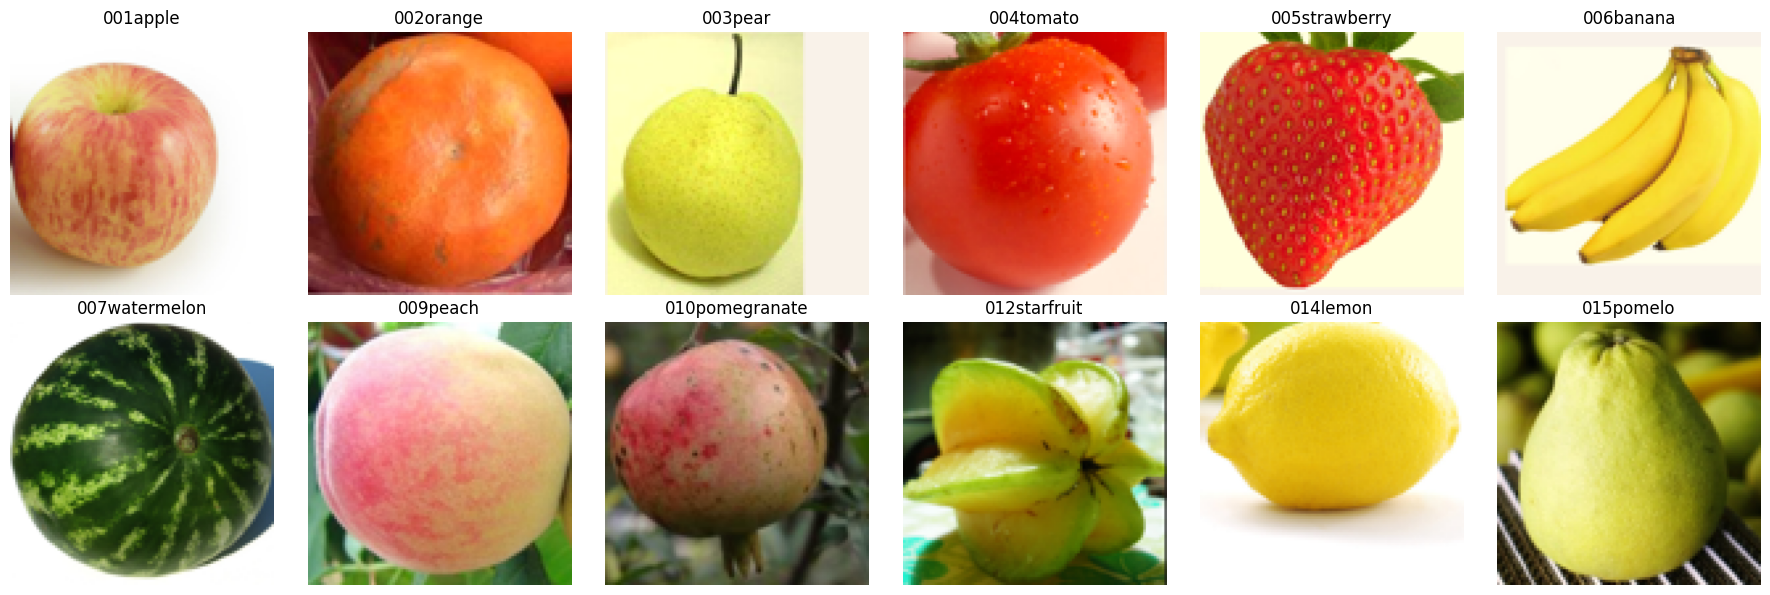

In [9]:
# Mengambil 1 sampel acak untuk setiap kelas dari dataframe manifest
if "manifest" not in globals():
    raise RuntimeError(
        "Variabel `manifest` belum tersedia. Jalankan sel Tahap 4 terlebih dahulu."
    )

sample_df = (
    manifest.groupby("source_class")
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Membuat figure grid 2 baris x 6 kolom
fig, axes = plt.subplots(nrows=2, ncols=6, figsize=(18, 6))
axes = axes.flatten()

for idx, row in sample_df.iterrows():
    # Membaca citra yang telah diproses
    img = cv2.imread(row['output_path'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Konversi BGR ke RGB untuk matplotlib
    
    # Menampilkan gambar dan nama kelasnya
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(row['source_class'], fontsize=12)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

## Tahap 6 - Analisis Ringkas dan Ekspor

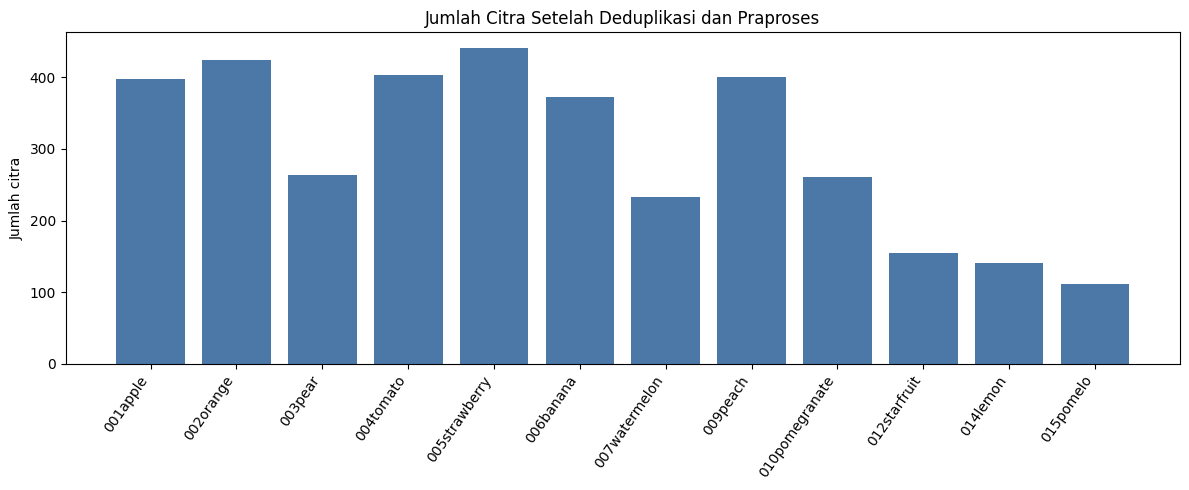

In [10]:
class_counts = manifest.groupby("source_class").size().rename("processed_image_count").reset_index()
write_csv(manifest, OUTPUT_DIR / "dataset_preparation_report.csv", ["subset", "source_class", "source_file_name"])
write_csv(pd.DataFrame(deduplication_rows, columns=["source_class", "duplicate_file"]), OUTPUT_DIR / "deduplication_report.csv", ["source_class", "duplicate_file"], allow_empty=True)
write_csv(pd.DataFrame(error_rows, columns=["stage", "source_class", "source_path"]), OUTPUT_DIR / "dataset_preparation_errors.csv", ["stage", "source_class", "source_path"], allow_empty=True)
write_csv(verification, OUTPUT_DIR / "dataset_preparation_verification.csv", ["source_class", "output_path"])
write_json({"method_version": METHOD_VERSION, "subset": SUBSET, "selected_classes": list(SELECTED_CLASSES), "raw_image_count": int(inventory.raw_image_count.sum()), "processed_image_count": int(len(manifest)), "duplicates_removed": int(len(deduplication_rows)), "preprocessing_errors": int(len(error_rows)), "output_size": OUTPUT_SIZE, "phash_threshold": PHASH_THRESHOLD}, OUTPUT_DIR / "dataset_preparation_summary.json")

plt.figure(figsize=(12, 5))
plt.bar(class_counts["source_class"], class_counts["processed_image_count"], color="#4C78A8")
plt.xticks(rotation=55, ha="right")
plt.ylabel("Jumlah citra")
plt.title("Jumlah Citra Setelah Deduplikasi dan Praproses")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_preparation_summary.png", dpi=180, bbox_inches="tight")
plt.show()
